# Bike Rental Demand Prediction (Regression)
    * Predict hourly bike rental demand (`cnt`) using weather, season, time and calendar information.
    * Prediction of daily bike rental count based on the environmental and seasonal settings.

## Project Overview
    * The Bike Sharing Demand Prediction project aims to predict the total number of bikes rented (cnt) based on factors such as season, year, month, hour, working day, weather conditions, temperature, humidity, wind speed, and engineered time-based features.

    * The hour.csv dataset was selected for modeling because it provides hourly-level information and therefore captures variations in bike demand throughout the day more effectively than daily-level data.
    
    Dataset Analysis
- The dataset contains information related to:
- Date and time
- Season and month
- Hour of the day
- Working day and holiday status
- Weather conditions
- Temperature and feeling temperature
- Humidity and wind speed
- Casual and registered users
- Total bike rentals

## Business case & Domain Analysis

A bike-sharing company needs to estimate the number of bikes that will be rented at a given hour.

Accurate demand prediction can help with:
- bike availability and redistribution
- staffing and maintenance planning
- reducing stock-outs
- improving customer experience
- operational planning

### Machine Learning problem
This is a **supervised regression problem** because the target (`cnt`) is a continuous numerical value.

### Target
* `cnt` = total number of bike rentals.

### Important leakage check
In this dataset:
 * `cnt = casual + registered`
 * Therefore, `casual` and `registered` must **not** be used as predictors when predicting `cnt`.


In [1]:
## Import required libraries
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
from sklearn.ensemble import ExtraTreesRegressor,GradientBoostingRegressor,RandomForestRegressor,HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit  # We use TimeSeriesSplit because Bike Sharing dataset is time-based.
from sklearn.inspection import permutation_importance
import joblib


## Basic checks

## Load the datasets
We have two files:
- `day.csv`: daily-level data
- `hour.csv`: hourly-level data
- For the main ML model we will use **`hour.csv`**, because hourly prediction is more detailed and useful for demand forecasting.


In [83]:
df1=pd.read_csv('day.csv')
df2=pd.read_csv('hour.csv')

In [3]:
df1.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [4]:
df2.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [5]:
print('Day dataset shape:',df1.shape)
print('Hour dataset shape:',df2.shape)

Day dataset shape: (731, 16)
Hour dataset shape: (17379, 17)


In [6]:
# Compare columns
print('Day columns:')
print(df1.columns.to_list())
print('Hour columns:')
print(df2.columns.to_list())

Day columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
Hour columns:
['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


In [7]:
# Check structure and data types
print('Day info :')
df1.info()
print('Hour info :')
df2.info()


Day info :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
Hour info :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 

In [8]:
# Discriptive statistics of hour dataset
df2.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


In [9]:
# Check Missing values with percentage wise
missing=df2.isnull().sum().sort_values(ascending=False)
missing_df=pd.DataFrame({
    'Missing':missing,
    'Missing Percentage':(missing/len(df2)*100)
})
missing_df

,Missing,Missing Percentage
instant,0,0.0
weathersit,0,0.0
registered,0,0.0
casual,0,0.0
windspeed,0,0.0
hum,0,0.0
atemp,0,0.0
temp,0,0.0
workingday,0,0.0
dteday,0,0.0


In [10]:
# Duplicate rows
print('Duplicate value',df2.duplicated().sum())

Duplicate value 0


In [11]:
# Check Unique value
unique_df=pd.DataFrame({
    'Column':df2.columns,
    'Unique values':[df2[c].nunique() for c in df2.columns]})
unique_df

,Column,Unique values
0,instant,17379
1,dteday,731
2,season,4
3,yr,2
4,mnth,12
5,hr,24
6,holiday,2
7,weekday,7
8,workingday,2
9,weathersit,4


# EDA(Exploratory Data Analysis)

### Check target distribution

count    17379.000000
mean       189.463088
std        181.387599
min          1.000000
25%         40.000000
50%        142.000000
75%        281.000000
max        977.000000
Name: cnt, dtype: float64

Text(0.5, 1.0, 'Distrbution of Target: cnt')

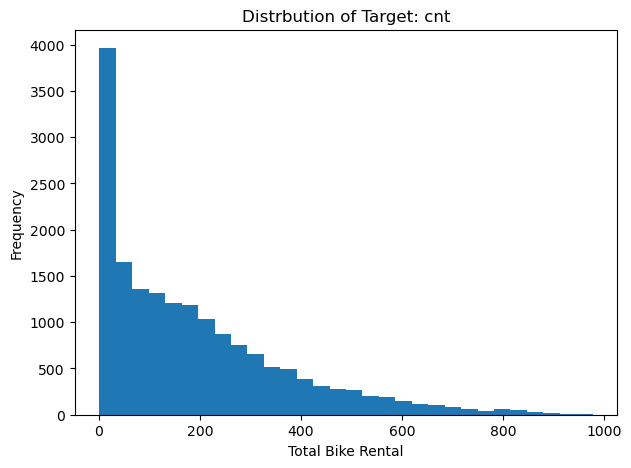

In [12]:
display(df2['cnt'].describe())
plt.figure(figsize=(7,5))
plt.hist(df2['cnt'],bins=30)
plt.xlabel('Total Bike Rental')
plt.ylabel('Frequency')
plt.title('Distrbution of Target: cnt')

**Insights**:“The target variable cnt shows a positively skewed distribution with a long right tail. The mean rental count (189.46) is higher than the median (142), indicating the influence of high-demand hours. Rental counts range from 1 to 977, with most observations concentrated at lower-to-moderate demand levels. Therefore, the target distribution should be considered during preprocessing and model development.”

## Understand the variable

Common variables in this dataset include:

- `season` — season category
- `yr` — year
- `mnth` — month
- `hr` — hour
- `holiday` — whether the day is a holiday
- `weekday` — day of week
- `workingday` — working day indicator
- `weathersit` — weather condition
- `temp` — normalized temperature
- `atemp` — normalized feeling temperature
- `hum` — normalized humidity
- `windspeed` — normalized wind speed
- `casual` — casual rentals
- `registered` — registered rentals
- `cnt` — total rentals / target

For prediction of `cnt`, we remove `casual` and `registered` because they directly form the target.


In [13]:
# Check the relationship cnt = casual + registered 
check=np.isclose(df2['cnt'],df2['casual']+ df2['registered'])
print('Rows where cnt= casual + registerd:',check.sum(),'out of',len(df2))

print('Target:','cnt')
print('Leakage columns:','[casual,registerd]')


Rows where cnt= casual + registerd: 17379 out of 17379
Target: cnt
Leakage columns: [casual,registerd]


## Target 'cnt' by hour

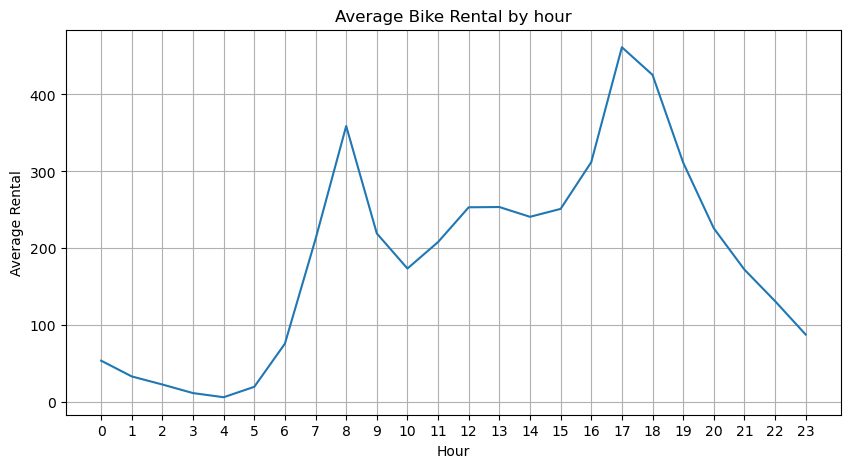

In [14]:
hour_mean=df2.groupby('hr')['cnt'].mean()
plt.figure(figsize=(10,5))
plt.plot(hour_mean.index,hour_mean.values)
plt.title('Average Bike Rental by hour')
plt.xlabel('Hour')
plt.ylabel('Average Rental')
plt.xticks(range(0,24))
plt.grid(True)
plt.show()


**Insights**:Bike rentals are lowest during the early morning hours (3 AM–5 AM), with demand increasing sharply from 6 AM and peaking around 8 AM.
* The highest average rental demand occurs around 5 PM (17:00), followed by a gradual decline during the evening.
* Rental demand is higher during commuting hours, suggesting that morning and evening peak periods are important for bike availability planning.

## Target 'cnt' by Month

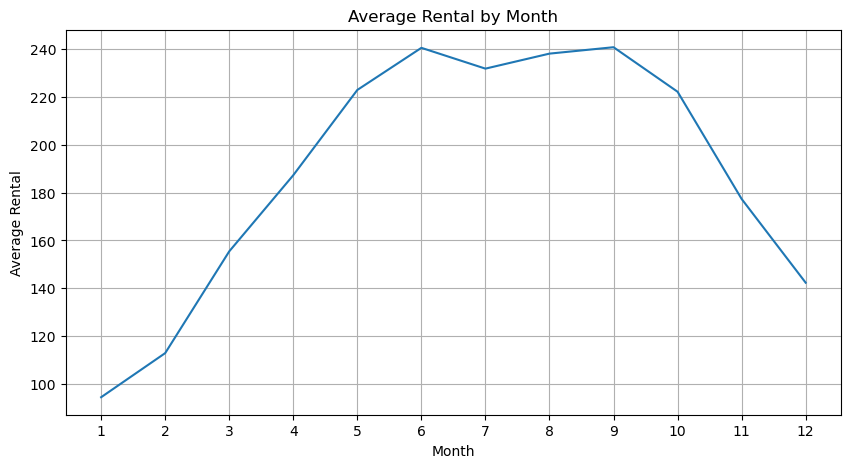

In [15]:
month_mean=df2.groupby('mnth')['cnt'].mean()
plt.figure(figsize=(10,5))
plt.plot(month_mean.index,month_mean.values)
plt.xlabel('Month')
plt.ylabel('Average Rental')
plt.title('Average Rental by Month')
plt.xticks(range(1,13))
plt.grid(True)
plt.show()

**Insights**: Bike rentals increase steadily from January and reach their highest levels during June and September, indicating stronger demand during these months.
* Rental demand declines significantly after October, reaching its lowest level in January, suggesting seasonal variations in bike rental usage.

## Target by Week day

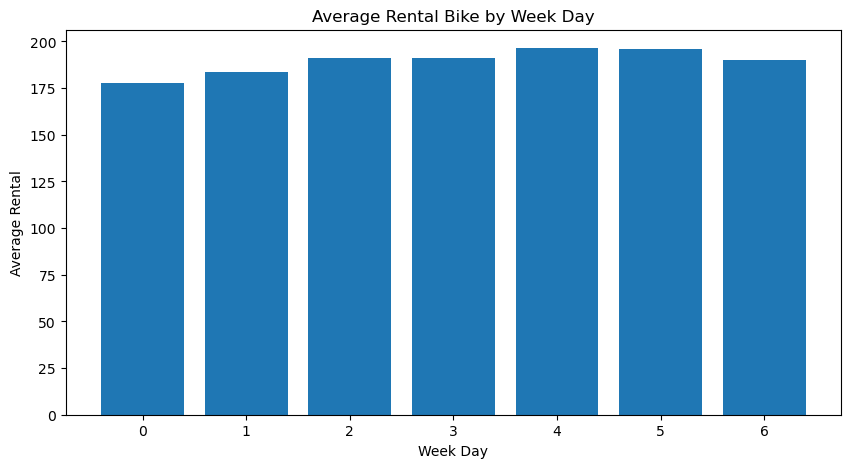

In [16]:
weekday_mean=df2.groupby('weekday')['cnt'].mean()
plt.figure(figsize=(10,5))
plt.bar(weekday_mean.index,weekday_mean.values)
plt.title('Average Rental Bike by Week Day')
plt.xlabel('Week Day')
plt.ylabel('Average Rental')
plt.show()


**Insights** Average bike rentals are steady throughout the week, ranging from about 178 to 197 per day.
They peak on day Thursday, with Friday nearly as high, and are lowest on day Sunday.

## Target by Weather Season

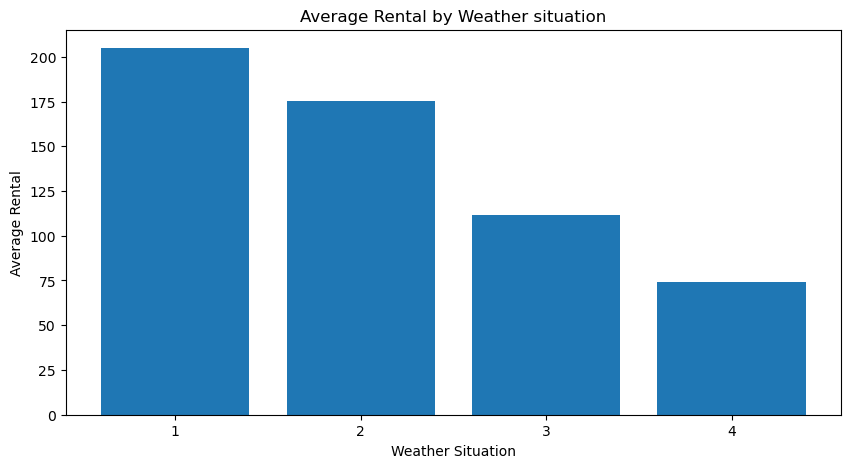

In [17]:
weather_mean=df2.groupby('weathersit')['cnt'].mean()
plt.figure(figsize=(10,5))
plt.bar(weather_mean.index.astype(str),weather_mean.values)
plt.title('Average Rental by Weather situation')
plt.xlabel('Weather Situation')
plt.ylabel('Average Rental')
plt.show()

**Insights** The visualization shows a strong negative relationship between poor weather and bike rentals:
- Weather 1 (clear/partly cloudy) has the highest average rentals: about 205.
- Weather 2 (mist/cloudy) drops to about 175 — roughly 15% lower than clear weather.
- Weather 3 (light rain/snow) falls further to about 112 — around 45% lower than clear weather.
- Weather 4 (heavy rain/snow/fog) has the lowest average: about 74 — roughly 64% below clear weather.
Key insight: weather condition is an important predictor of bike demand. As weather worsens, average rentals consistently decrease, so the ML model should retain weathersit as a key feature.
One caution: weather category 4 usually has very few records in this dataset, so its average may be less reliable than categories 1–3.

## Working Day by Comparison

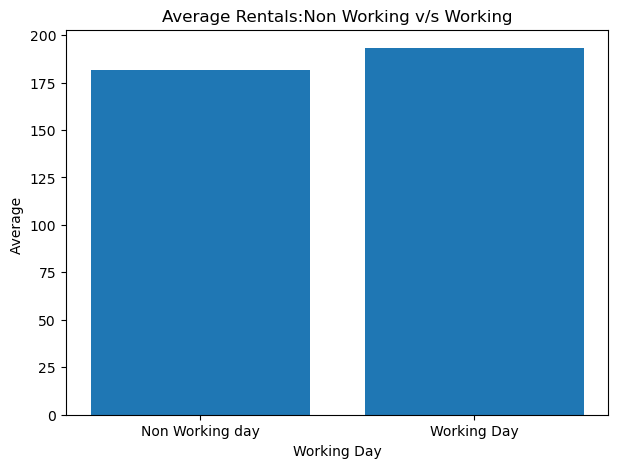

In [18]:
working_mean=df2.groupby('workingday')['cnt'].mean()
plt.figure(figsize=(7,5))
plt.bar(['Non Working day','Working Day'],working_mean.values)
plt.xlabel('Working Day')
plt.ylabel('Average ')
plt.title('Average Rentals:Non Working v/s Working')
plt.show()

**Insights** : Working days have slightly higher average bike rentals than non-working days.
- Non-working days: about 182 average rentals
- Working days: about 193 average rentals
- Difference: around 11 rentals, or roughly 6% higher demand on working days
Insight: bike rentals remain strong on both types of days, but the increase on working days suggests commuting contributes to demand. workingday should be included as an ML feature, though its effect appears smaller than weather conditions.

## Correlation matrix v/s Numerical Variables

In [19]:
numerical_cols=['instant','season','yr','mnth','hr','holiday','weekday','workingday','weathersit','temp','atemp','hum','windspeed','casual', 
            'registered','cnt']


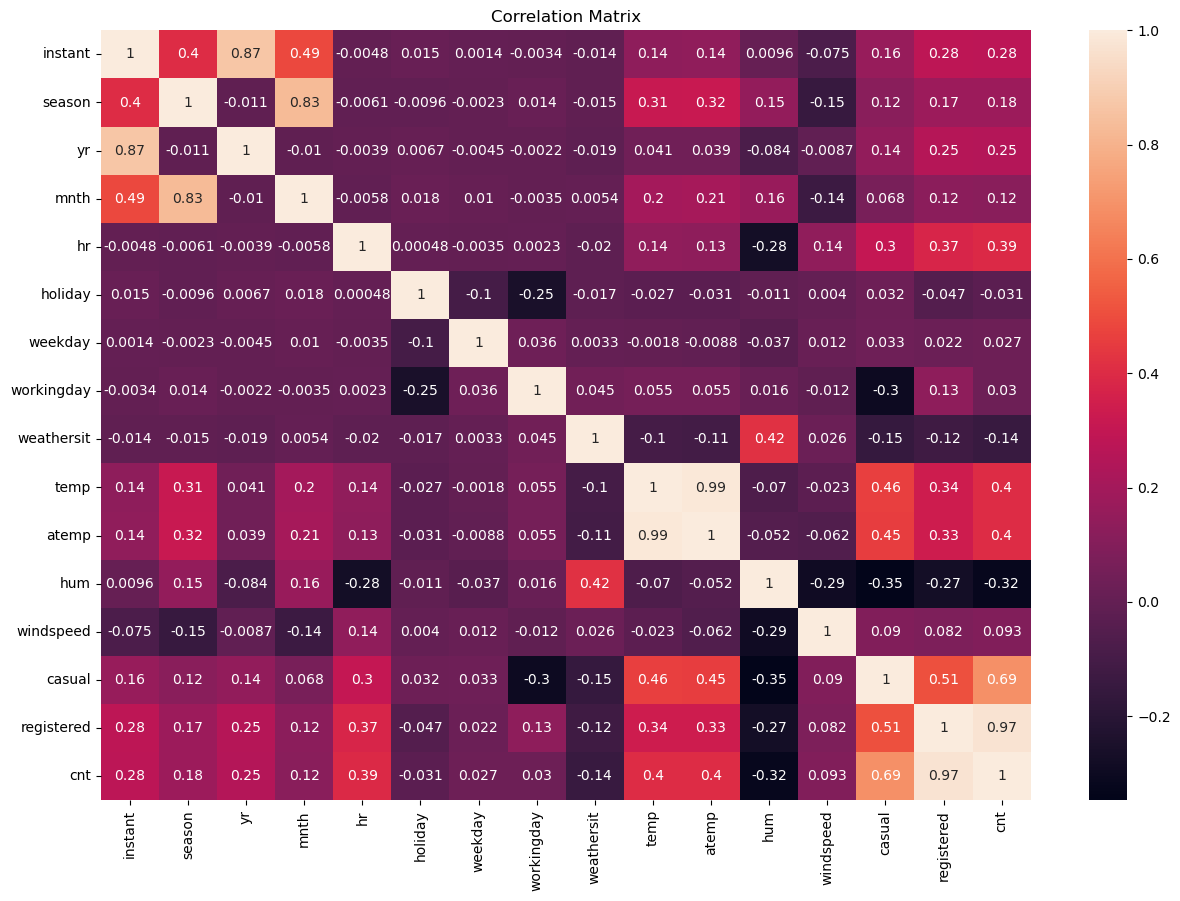

In [20]:
corr=df2[numerical_cols].corr()
plt.figure(figsize=(15,10))
sns.heatmap(corr,annot=True)
plt.title('Correlation Matrix')
plt.show()

**Insights**:- registered users have the strongest correlation with total rentals (cnt) at about 0.97, followed by casual users at about 0.69.
  Do not use registered or casual as ML input features because cnt = registered + casual; this would cause data leakage.
- Hour (hr) has a moderate positive correlation with rentals (about 0.39), showing that time of day strongly affects demand. This is expected because commuting and peak-hour travel drive rentals.
- Temperature (temp) and feeling temperature (atemp) both correlate positively with rentals (about 0.40). Warmer conditions generally increase bike use.
- Humidity (hum) has a moderate negative relationship with rentals (about -0.32). Higher humidity tends to reduce demand.
- Weather situation (weathersit) has a negative correlation with rentals (about -0.14): worse weather means fewer rentals.
- Year (yr) has a positive correlation with rentals (about 0.25), suggesting demand increased from 2011 to 2012.
- temp and atemp are almost perfectly correlated (about 0.99). For a linear regression model, keep only one of them to avoid multicollinearity. Tree-based models can generally handle both, but keeping one still simplifies the model.
- Holiday, weekday, and working-day variables have very weak linear correlations with rentals. They may still matter through interactions with hour, season, and weather.
Important note: correlation measures only linear relationships; it does not prove causation or capture non-linear patterns.

# Feature Engineering
    * We will create time-based features. 

### Why feature engineering?
Raw `hr`, `mnth` and `weekday` are categorical/time variables. We can provide the model with additional information about the cyclical nature of time.

Examples:
- rush hour indicator
- weekend indicator
- temperature interaction
- cyclical hour encoding

### Important
We will create features **without using `casual`, `registered`, or future target information**.


In [21]:
df2.shape

(17379, 17)

In [22]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [23]:
# Make Model a copy
df=df2.copy()

# Date column
df['dteday']=pd.to_datetime(df['dteday'])

# Basic time features

df['day_of_month']=df['dteday'].dt.day
df['is_weekend']=df['weekday'].isin([0,6]).astype(int)

# Rush-hour Indicator

df['is_rush_hour']=df['hr'].isin([7,8,9,16,17,18,19]).astype(int)

#Morning/evening indicator
df['is_morning']=df['hr'].between(6,11).astype(int)
df['is_evening']=df['hr'].between(16,21).astype(int)

# Cyclic hour encoding

df['hr_sin']=np.sin(2 * np.pi * df['hr']/24)
df['hr_cos']=np.cos(2 * np.pi * df['hr']/24)

# Cyclic Month encoding

df['mnth_sin']=np.sin(2 * np.pi * df['mnth']/12)
df['mnth_cos']=np.cos(2 * np.pi * df['mnth']/12)

# Temprature Interaction

df['temp_hum']= df['temp'] * df['hum']



In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 27 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   instant       17379 non-null  int64         
 1   dteday        17379 non-null  datetime64[ns]
 2   season        17379 non-null  int64         
 3   yr            17379 non-null  int64         
 4   mnth          17379 non-null  int64         
 5   hr            17379 non-null  int64         
 6   holiday       17379 non-null  int64         
 7   weekday       17379 non-null  int64         
 8   workingday    17379 non-null  int64         
 9   weathersit    17379 non-null  int64         
 10  temp          17379 non-null  float64       
 11  atemp         17379 non-null  float64       
 12  hum           17379 non-null  float64       
 13  windspeed     17379 non-null  float64       
 14  casual        17379 non-null  int64         
 15  registered    17379 non-null  int64 

In [25]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,day_of_month,is_weekend,is_rush_hour,is_morning,is_evening,hr_sin,hr_cos,mnth_sin,mnth_cos,temp_hum
0,1,2011-01-01,1,0,1,0,0,6,0,1,...,1,1,0,0,0,0.000000,1.000000,0.5,0.866025,0.1944
1,2,2011-01-01,1,0,1,1,0,6,0,1,...,1,1,0,0,0,0.258819,0.965926,0.5,0.866025,0.1760
2,3,2011-01-01,1,0,1,2,0,6,0,1,...,1,1,0,0,0,0.500000,0.866025,0.5,0.866025,0.1760
3,4,2011-01-01,1,0,1,3,0,6,0,1,...,1,1,0,0,0,0.707107,0.707107,0.5,0.866025,0.1800
4,5,2011-01-01,1,0,1,4,0,6,0,1,...,1,1,0,0,0,0.866025,0.500000,0.5,0.866025,0.1800


In [26]:
df.shape

(17379, 27)

In [27]:
df.columns

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt', 'day_of_month', 'is_weekend',
       'is_rush_hour', 'is_morning', 'is_evening', 'hr_sin', 'hr_cos',
       'mnth_sin', 'mnth_cos', 'temp_hum'],
      dtype='object')

In [28]:
df['day_of_month'].value_counts() # It tells the model which day of the month the rental occurred.

day_of_month
1     575
5     575
17    575
9     575
13    574
21    574
20    574
19    574
15    574
14    574
16    574
8     574
7     574
4     574
12    573
23    573
2     573
3     573
24    573
10    572
25    572
6     572
22    569
11    568
26    567
18    563
28    563
27    552
29    526
30    514
31    336
Name: count, dtype: int64

In [29]:
df['weekday'].value_counts() # Bike usage can behave differently on weekends.

weekday
6    2512
0    2502
5    2487
1    2479
3    2475
4    2471
2    2453
Name: count, dtype: int64

 For example:
* Working day → commuting → morning/evening peaks
* Weekend → leisure/recreational trips → different demand pattern

In [30]:
df['is_rush_hour'].value_counts()

is_rush_hour
0    12282
1     5097
Name: count, dtype: int64

* Bike rentals can increase during commuting hours.
* Instead of asking the model to discover that:
* 7, 8, 9 and 17, 18, 19 are special hours
* we explicitly give it a feature saying:
* "This is a rush hour."


In [31]:
df['is_morning'].value_counts()

is_morning
0    13019
1     4360
Name: count, dtype: int64

* It tells the model whether the rental occurred during the morning period.
* Why useful?
    * Morning demand may have a different pattern from afternoon/night demand.
* However, because you already have hr, this may not add much for powerful tree models.

In [32]:
df['is_evening'].value_counts()

is_evening
0    13007
1     4372
Name: count, dtype: int64

* It identifies the evening period.
* Again, it tries to give the model a higher-level pattern:
* "This observation is during the evening."

In [33]:
df['hr_cos'].value_counts()

hr_cos
-2.588190e-01    1457
 5.000000e-01    1425
-5.000000e-01     730
-7.071068e-01     729
-8.660254e-01     729
-9.659258e-01     729
 9.659258e-01     728
-1.000000e+00     728
 8.660254e-01     728
 7.071068e-01     728
 2.588190e-01     728
-1.836970e-16     728
-9.659258e-01     727
-8.660254e-01     727
-7.071068e-01     727
-5.000000e-01     727
 1.000000e+00     726
 6.123234e-17     725
 9.659258e-01     724
 2.588190e-01     717
 8.660254e-01     715
 7.071068e-01     697
Name: count, dtype: int64

* We need both sin and cos because together they represent the position of the hour on a 24-hour circle.
* Why two columns?
      * Because one sine value alone cannot uniquely represent every position around the circle.
So:
- **hour**
-     ↓
- **hr_sin**
- **hr_cos**
 * together describe the hour's position.
    * These are particularly useful for linear models.

In [34]:
df['hr_sin'].value_counts()

hr_sin
 9.659258e-01    1444
 5.000000e-01    1442
 7.071068e-01    1424
-8.660254e-01     730
-9.659258e-01     730
-2.588190e-01     729
-5.000000e-01     729
-7.071068e-01     729
-5.000000e-01     728
-7.071068e-01     728
-8.660254e-01     728
-9.659258e-01     728
-1.000000e+00     728
-2.588190e-01     728
 1.224647e-16     728
 2.588190e-01     727
 8.660254e-01     727
 0.000000e+00     726
 1.000000e+00     725
 2.588190e-01     724
 8.660254e-01     697
Name: count, dtype: int64

* This tells the model that the calendar is cyclical, not a straight line.

In [35]:
df['temp_hum'].value_counts()

temp_hum
0.1560    187
0.5180    166
0.4884    153
0.1800    120
0.2100    119
         ... 
0.3182      1
0.4864      1
0.5376      1
0.4374      1
0.2054      1
Name: count, Length: 776, dtype: int64

* As we check all features we added at last with their use ...so we keep useful features and another feature we may remove
    -day_of_month
    -is_morning
    -is_evening
    -temp_hum 
these are not required more

In [36]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,day_of_month,is_weekend,is_rush_hour,is_morning,is_evening,hr_sin,hr_cos,mnth_sin,mnth_cos,temp_hum
0,1,2011-01-01,1,0,1,0,0,6,0,1,...,1,1,0,0,0,0.000000,1.000000,0.5,0.866025,0.1944
1,2,2011-01-01,1,0,1,1,0,6,0,1,...,1,1,0,0,0,0.258819,0.965926,0.5,0.866025,0.1760
2,3,2011-01-01,1,0,1,2,0,6,0,1,...,1,1,0,0,0,0.500000,0.866025,0.5,0.866025,0.1760
3,4,2011-01-01,1,0,1,3,0,6,0,1,...,1,1,0,0,0,0.707107,0.707107,0.5,0.866025,0.1800
4,5,2011-01-01,1,0,1,4,0,6,0,1,...,1,1,0,0,0,0.866025,0.500000,0.5,0.866025,0.1800


### Remove unnecessary columns
- casual — target component / leakage
- registered — target component / leakage
- instant — row/index identifier
- dteday — raw date is removed after extracting useful date features
- day_of_month - it shows monthly position
- is_morning - it shows morning period
- is_evening - it shows evening period
- temp_hum  - it shows temperature * humidity

In [37]:
drop_columns=['casual','registered','instant','dteday','day_of_month','is_morning','is_evening','temp_hum']

In [38]:
df=df.drop(columns=drop_columns,axis=1)

In [39]:
df

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt,is_weekend,is_rush_hour,hr_sin,hr_cos,mnth_sin,mnth_cos
0,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,16,1,0,0.000000,1.000000,5.000000e-01,0.866025
1,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,40,1,0,0.258819,0.965926,5.000000e-01,0.866025
2,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,32,1,0,0.500000,0.866025,5.000000e-01,0.866025
3,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,13,1,0,0.707107,0.707107,5.000000e-01,0.866025
4,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,1,1,0,0.866025,0.500000,5.000000e-01,0.866025
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,119,0,1,-0.965926,0.258819,-2.449294e-16,1.000000
17375,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,89,0,0,-0.866025,0.500000,-2.449294e-16,1.000000
17376,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,90,0,0,-0.707107,0.707107,-2.449294e-16,1.000000
17377,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,61,0,0,-0.500000,0.866025,-2.449294e-16,1.000000


## Define x and y
    * target = 'cnt'

In [40]:
x=df.drop('cnt',axis=1)
y=df['cnt']

In [41]:
print('X Shape:',x.shape)
print('y Shape:',y.shape)

X Shape: (17379, 18)
y Shape: (17379,)


## Train-test , split
* We use an 80/20 split.
* Because this is demand prediction and the data has a time structure, we also avoid randomly mixing future observations into the training process by using a chronological split.
* The first 80% is training data and the final 20% is test data.


In [42]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.20)

In [43]:
print('x train:',x_train.shape)
print('X test:',x_test.shape)
print('Y test:',y_test.shape)
print('Y train:',y_train.shape)

x train: (13903, 18)
X test: (3476, 18)
Y test: (3476,)
Y train: (13903,)


## Identifies Numeric and Categorical Feature

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   season        17379 non-null  int64  
 1   yr            17379 non-null  int64  
 2   mnth          17379 non-null  int64  
 3   hr            17379 non-null  int64  
 4   holiday       17379 non-null  int64  
 5   weekday       17379 non-null  int64  
 6   workingday    17379 non-null  int64  
 7   weathersit    17379 non-null  int64  
 8   temp          17379 non-null  float64
 9   atemp         17379 non-null  float64
 10  hum           17379 non-null  float64
 11  windspeed     17379 non-null  float64
 12  cnt           17379 non-null  int64  
 13  is_weekend    17379 non-null  int64  
 14  is_rush_hour  17379 non-null  int64  
 15  hr_sin        17379 non-null  float64
 16  hr_cos        17379 non-null  float64
 17  mnth_sin      17379 non-null  float64
 18  mnth_cos      17379 non-nu

In [45]:
categorical_features=['season','yr','mnth','hr','holiday','weekday','workingday','weathersit','is_weekend','is_rush_hour']
numerical_features=['temp','atemp','hum','windspeed','hr_sin','hr_cos','mnth_sin','mnth_cos']
target=['cnt']

## Create a processing pipeline

In [46]:
numrical_transformer=Pipeline(steps=[('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())])

In [47]:
categorical_transformer=Pipeline(steps=[('imputer',SimpleImputer(strategy='most_frequent')),
                                        ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])

In [48]:
preprocessor=ColumnTransformer(transformers=[('num',numrical_transformer,numerical_features),
                                             ('cat',categorical_transformer,categorical_features)])

In [49]:
preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


# Create Model

In [50]:
#linear_model=Pipeline(steps=[('Preprocessor',preprocessor),('Model',LinearRegression())])

In [51]:
#linear_model.fit(x_train,y_train)

In [52]:
#y_pred_linear=linear_model.predict(x_test)

In [53]:
# Model Creation 
models={
    'Linear Regression':LinearRegression(),
    'Ridge':Ridge(alpha=1.0),
    'Random Forest':RandomForestRegressor(n_estimators=200,random_state=42,n_jobs=-1),
    'Extra Trees':ExtraTreesRegressor(n_estimators=200,random_state=42,n_jobs=-1),
    'Gradient Boosting':GradientBoostingRegressor(random_state=42),
    'HistGradient Boosting':HistGradientBoostingRegressor(random_state=42)
}

In [54]:
# Model Fitted in Pipeline
results=[]
fitted_models={}

for name,model in models.items():
    pipe=Pipeline(steps=[
        ('preprocessor',preprocessor),('model',model)
    ])
    pipe.fit(x_train,y_train)
    pred=pipe.predict(x_test)

    mae=mean_absolute_error(y_test,pred)
    rmse=np.sqrt(mean_squared_error(y_test,pred))
    r2=r2_score(y_test,pred)

    results.append({
        'Model':name,
        'MAE':mae,
        'RMSE':rmse,
        'R2':r2
    })
    fitted_models[name]=pipe
    
result_df=pd.DataFrame(results).sort_values('RMSE')

display(result_df)
    


,Model,MAE,RMSE,R2
5,HistGradient Boosting,25.889839,40.819104,0.947381
2,Random Forest,24.503065,42.006049,0.944276
3,Extra Trees,25.620291,44.247880,0.938170
4,Gradient Boosting,43.433214,61.713223,0.879726
1,Ridge,74.096227,100.428196,0.681488
0,Linear Regression,74.105159,100.445946,0.681375


* HistGradientBoosting performed best, achieving the highest R² of 94.74% and lowest RMSE of 40.82.
* Random Forest had the lowest MAE (24.50), showing slightly lower average absolute error.
* Linear Regression performed weaker, with R² of only 68.14% and RMSE of 100.45.

## Model Comparison Visualization

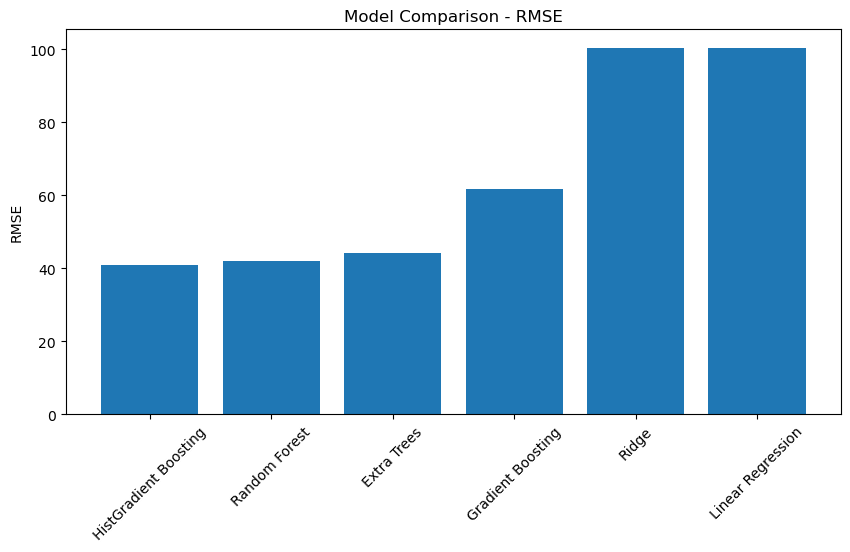

In [55]:
plt.figure(figsize=(10,5))
plt.bar(result_df['Model'],result_df['RMSE'])
plt.ylabel('RMSE')
plt.title('Model Comparison - RMSE')
plt.xticks(rotation=45)
plt.show()

## Select the best Model
A practical approach:
- lower MAE means smaller average absolute prediction error
- lower RMSE penalizes large errors more strongly
- higher R² means more variance is explained

The final choice should consider all three metrics and the business objective.


In [56]:
# select best model name
best_model_name=result_df.iloc[0]['Model']
best_baseline_model=fitted_models[best_model_name]

print('Best Model according lowest RMSE :')
print(best_model_name)

Best Model according lowest RMSE :
HistGradient Boosting


## Hyperparameter Tuning

* Now we tune a tree-based model.
    - The exact model to tune is selected from the baseline comparison. We use HistGradient Boosting
         here because it is easy to interpret and provides feature importance.
    - If another model performs substantially better in your results, you can tune that model instead.


In [57]:
# HistGradientBoosting Tuning
hgb_pipe=Pipeline(steps=[('Preprocesor',preprocessor),
                    ('model',HistGradientBoostingRegressor(random_state=42))
    
])

In [58]:
# hyper parameter
param_grid={
    'model__learning_rate':[0.03,0.05,0.08,0.1],
    'model__max_iter':[100,200,300,400],
    'model__max_leaf_nodes':[15,31,63,127],
    'model__max_depth':[None,5,10,15],
    'model__min_samples_leaf':[10,20,30,50],
    "model__l2_regularization":[0,0.1,1,5]
    
}

In [59]:
#TimeSeriesSplit
tscv=TimeSeriesSplit(n_splits=5)

In [60]:
# RandomSearchCV
random_search=RandomizedSearchCV(estimator=hgb_pipe,param_distributions=param_grid,n_iter=30,
                   cv=tscv,scoring='neg_root_mean_squared_error',random_state=42,n_jobs=-1,verbose=1)

In [61]:
random_search.fit(x_train,y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,estimator,Pipeline(step...m_state=42))])
,param_distributions,"{'model__l2_regularization': [0, 0.1, ...], 'model__learning_rate': [0.03, 0.05, ...], 'model__max_depth': [None, 5, ...], 'model__max_iter': [100, 200, ...], ...}"
,n_iter,30
,scoring,'neg_root_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,TimeSeriesSpl...est_size=None)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [62]:
# print best parameters and Best CV
print('Best Parameters:')
print(random_search.best_params_)
print('Best CV RMSE:',random_search.best_score_)
random_search.best_estimator_

Best Parameters:
{'model__min_samples_leaf': 10, 'model__max_leaf_nodes': 31, 'model__max_iter': 400, 'model__max_depth': None, 'model__learning_rate': 0.05, 'model__l2_regularization': 5}
Best CV RMSE: -43.84024944130517


,steps,"[('Preprocesor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [63]:
tuned_hgb=random_search.best_estimator_

In [64]:
y_pred_tuned=tuned_hgb.predict(x_test)

In [65]:
mae_tuned=mean_absolute_error(y_test,y_pred_tuned)
rmse_tuned=np.sqrt(mean_squared_error(y_test,y_pred_tuned))
r2_tuned=r2_score(y_test,y_pred_tuned)

In [66]:
# print Evalution of hyper tuned of HGB
print('Tuned HistGradientBoosting Results :')
print('--------------------------------------')
print('MAE :',mae_tuned)
print('RMSE :',rmse_tuned)
print('R2 Score :',r2_tuned)

Tuned HistGradientBoosting Results :
--------------------------------------
MAE : 25.045375899948468
RMSE : 40.08070299564188
R2 Score : 0.9492675861508447


In [67]:
# Compare models
comparison=pd.DataFrame([{
    'Model':best_model_name,
    'MAE':result_df.iloc[0]['MAE'],
    'RMSE':result_df.iloc[0]['RMSE'],
    'R2':result_df.iloc[0]['R2']
        },
        {
            'Model': 'Tuned Model',
            'MAE':mae_tuned,
            'RMSE':rmse_tuned,
            'R2':r2_tuned
        }
    ])
display(comparison)

,Model,MAE,RMSE,R2
0,HistGradient Boosting,25.889839,40.819104,0.947381
1,Tuned Model,25.045376,40.080703,0.949268


## Actual vs Predicted value

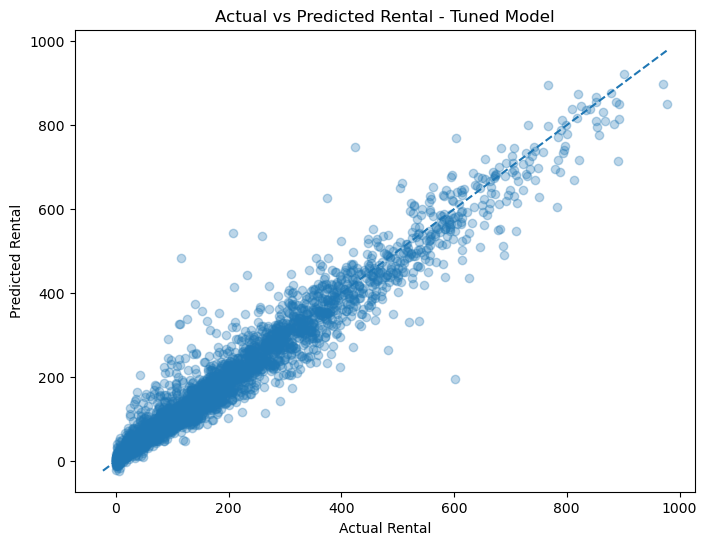

In [68]:
plt.figure(figsize=(8,6))
plt.scatter(y_test,y_pred_tuned,alpha=0.3)
min_val=min(y_test.min(),y_pred_tuned.min())
max_val=max(y_test.max(),y_pred_tuned.max())
plt.plot([min_val,max_val],[min_val,max_val],linestyle="--")
plt.xlabel('Actual Rental')
plt.ylabel('Predicted Rental')
plt.title('Actual vs Predicted Rental - Tuned Model')
plt.show()

**Insights** :The tuned model performs well overall because most points lie close to the dashed diagonal line, where predicted rental equals actual rental.
- The model captures the overall demand trend: low actual rentals receive low predictions, while high actual rentals receive high predictions.
- Prediction accuracy is strongest in the low-to-medium rental range, roughly 0–500 rentals, where points are densely clustered around the diagonal.
- There are some noticeable outliers. For example, a few actual values around 500–600 are predicted much lower or higher than expected. These represent days/hours the model struggles to explain.
- At high rental levels (around 700–950), predictions show more spread. The model sometimes underpredicts peak demand, which could lead to insufficient bike availability during busy periods.
- Some points below zero on the prediction axis indicate the regression model can produce negative rental predictions. Since rentals cannot be negative, clip predictions at zero before deployment:

## Residual Analysis
Residual:

`Residual = Actual - Predicted`

Ideally:
- residuals should be centered around zero
- there should not be a strong pattern
- very large residuals indicate difficult observations


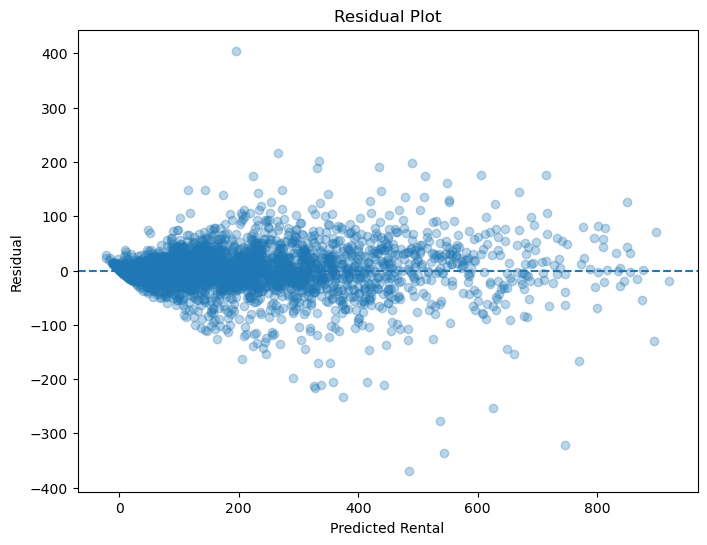

In [69]:
Residuals=y_test - y_pred_tuned

plt.figure(figsize=(8,6))
plt.scatter(y_pred_tuned,Residuals,alpha=0.3)
plt.axhline(0,linestyle='--')
plt.title('Residual Plot')
plt.xlabel('Predicted Rental')
plt.ylabel('Residual')
plt.show()


**Insights** The residual plot is mostly centered around the zero line, which is a good sign: the tuned model does not show a strong systematic overprediction or underprediction across most rental levels.
- Residual = Actual rental − Predicted rental.
  - Positive residual: the model underpredicted demand.
  - Negative residual: the model overpredicted demand.
- For low predicted rentals, residuals are tightly clustered near zero. The model is most stable for low-demand periods.
- As predicted rentals increase, the spread of residuals becomes wider. This indicates heteroscedasticity: prediction errors are larger during medium- and high-demand periods.
- There are several major outliers, with residuals approximately from -370 to +400. These are cases where the model misses demand substantially, likely due to unusual weather, peak commuting patterns, holidays, or events not included in the features.
- Residuals appear slightly more negative at some higher predicted values, meaning the model may overpredict demand in some high-rental scenarios. However, there is no very strong curved pattern, so the overall model fit remains reasonable.
Conclusion: the model works well for normal demand levels, but peak and unusual-demand periods need improvement. Adding event data, more detailed weather information, lagged demand features, or separate peak-hour modelling could reduce these larger errors.

In [70]:
# Residual summary
print("Mean Residuals:",Residuals.mean())
print('Median Residuals:',Residuals.median())
print('Standard Residuals',Residuals.std())

Mean Residuals: -0.27733400267997727
Median Residuals: -1.4705183342965142
Standard Residuals 40.085509947883345


## Feature Importance
- We use Permutation Importance to identify which features are most important for our machine-learning model's predictions.
- In your Bike Rental Demand Prediction project, it helps us understand which factors influence the model's predictions of bike rental counts.


In [78]:
# Calculate Permutation importance
perm_importance=permutation_importance(tuned_hgb,x_test,y_test,scoring='r2',n_repeats=10,random_state=42,n_jobs=-1)

# create Feature Importance Dataframe
feature_importance=pd.DataFrame({
    'Feature':x_test.columns,
    'Importance':perm_importance.importances_mean
})

# Short values
feature_importance=feature_importance.sort_values(by='Importance',ascending=False)
display(feature_importance)



,Feature,Importance
15,hr_cos,0.433140
14,hr_sin,0.391772
1,yr,0.186284
6,workingday,0.149287
8,temp,0.094399
13,is_rush_hour,0.059067
0,season,0.035917
3,hr,0.034790
10,hum,0.034130
12,is_weekend,0.032884


## Visualize feature importance

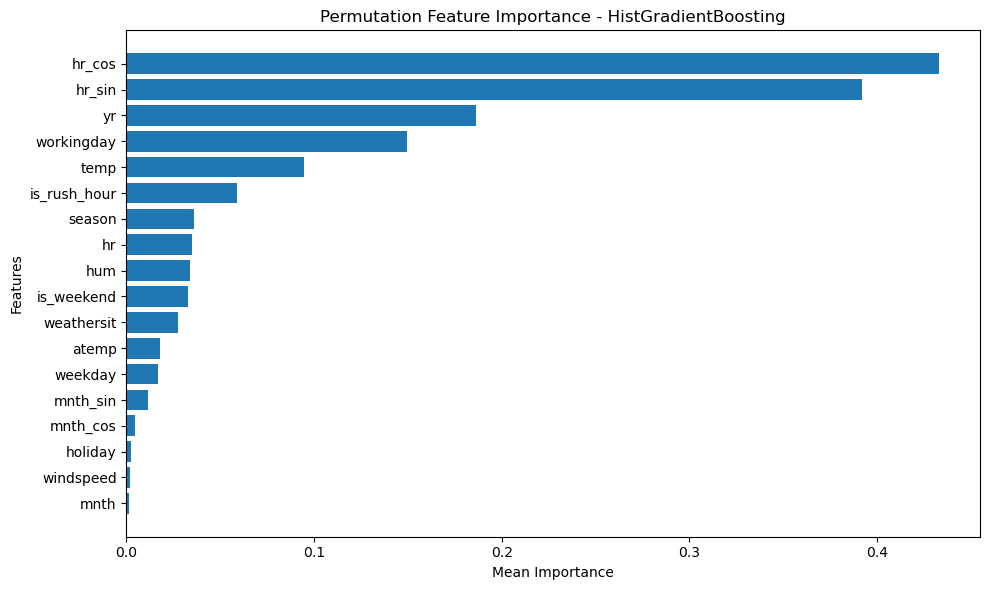

In [82]:
plt.figure(figsize=(10,6))
plt.barh(
    feature_importance['Feature'],
    feature_importance['Importance']
)
plt.xlabel('Mean Importance')
plt.ylabel('Features')
plt.title('Permutation Feature Importance - HistGradientBoosting')
plt.tight_layout()
plt.gca().invert_yaxis()
plt.show()


## Model Comparison Report 

- Linear Regression and Ridge Regression produced considerably higher RMSE and lower R², indicating that a simple linear relationship does not capture all the complex patterns in bike rental demand.
- Gradient Boosting substantially improved the results compared with the linear models.
- Extra Trees and Random Forest produced much lower prediction errors and higher R² scores, indicating that tree-based models can capture nonlinear relationships in the data.
- HistGradientBoosting achieved the highest R² (approximately 94.74%) and the lowest RMSE (approximately 40.82) among the evaluated models. Random Forest produced the lowest MAE at approxim
ately 24.50.
- **Model Selection**
- Based on the combination of R² and RMSE, HistGradientBoosting was selected as the candidate final model for hyperparameter tuning.
- The reason is:
- Highest R² → 94.74%
- Lowest RMSE → 40.82
- After tuning, the tuned HistGradientBoosting model should be evaluated again on the untouched test set before declaring it the final production model.

## Hyper parameter tuning Report

- Since HistGradientBoosting performed strongly in the baseline comparison, hyperparameter tuning was performed on this model.
- TimeSeriesSplit was used during cross-validation because the dataset contains chronological observations.
-The tuning process explored parameters such as:
* learning_rate
* max_iter
* max_leaf_nodes
* max_depth
* min_samples_leaf
* l2_regularization
- The objective was to find a parameter combination that improves predictive performance while avoiding overfitting.

- **Important point**
- The tuned model should be compared with the baseline model using the same untouched test set.
- If the tuned model gives:
    - Lower RMSE
    - Lower MAE
     - Higher R²
- then tuning has improved the model.

## Challenges Faced

**Challenge 1** — Understanding the dataset

The dataset contains several time, weather, and user-related variables. Understanding the meaning and role of each feature was important before model development.

**Challenge 2** — Target Leakage

The target variable is: `cnt`

cnt = casual + registered

Using casual and registered as input features would allow the model to indirectly know the target. Therefore, these columns were removed from the feature set.

**Challenge 3** — Time-dependent data

Bike rental demand changes with time. Randomly splitting the dataset could allow future information to enter the training data.

Therefore, chronological splitting and TimeSeriesSplit were used.

**Challenge 4** — Capturing cyclic patterns

Hour and month are cyclical variables. For example:23 → 0,
December → January

Therefore, cyclic features such as  : 
hr_sin
hr_cos
mnth_sin
mnth_cos

**Challenge 5** — Nonlinear relationships

Bike demand does not have a simple linear relationship with temperature, humidity, weather, hour, and season.

Therefore, multiple regression algorithms were compared, including tree-based ensemble models.

**Challenge 5 — Nonlinear relationships

Bike demand does not have a simple linear relationship with temperature, humidity, weather, hour, and season.

Therefore, multiple regression algorithms were compared, including tree-based ensemble models

**Challenge 6** — Model selection

Different models performed differently across MAE, RMSE, and R².

For example, Random Forest had the lowest MAE, while HistGradientBoosting had the highest R² and lowest RMSE.

Therefore, model selection required consideration of multiple evaluation metrics rather than relying on a single metric.

**Challenge 7** — Hyperparameter tuning

Finding suitable hyperparameters for ensemble models can be computationally expensive.

RandomizedSearchCV was used to efficiently search through combinations of parameters



## Conclusion

* The Bike Sharing Demand Prediction project successfully developed machine-learning models to predict hourly bike rental demand using weather, seasonal, calendar, and time-related features.

* Several regression models were compared using MAE, RMSE, and R². Among the baseline models, HistGradientBoosting achieved the highest R² of approximately 94.74% and the lowest RMSE of approximately 40.82, while Random Forest achieved the lowest MAE of approximately 24.50.

* Feature engineering, particularly the creation of time-based and cyclic features, helped the models capture hourly and seasonal demand patterns. Time-aware data splitting and TimeSeriesSplit were used to avoid inappropriate mixing of future and past observations.

* HistGradientBoosting was therefore selected as the candidate model for hyperparameter tuning. The final tuned model should be evaluated on the untouched test set and saved as the final prediction pipeline if it demonstrates satisfactory generalization performance.

## Select and Save the Final Model

In [89]:
# select the final model and final trained pipeline

final_model=tuned_hgb
display(final_model)

# save the complete pipeline

joblib.dump(final_model,'bike_rental_final_model.pkl')
print('Final model saved successfully !')

,steps,"[('Preprocesor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Final model saved successfully !


## Load and save the Model 

In [91]:
loaded_model=joblib.load('bike_rental_final_model.pkl')
print('Model loaded Successfully !')

Model loaded Successfully !


## Test and saved Model

In [97]:
# Load the saved Model
y_pred_saved=loaded_model.predict(x_test)

# Display actual and predicted values

prediction_result=pd.DataFrame({
    'Actual Rental':y_test.values,
    'Predicted Rental':y_pred_saved
            
})
display(prediction_result.head(10))

,Actual Rental,Predicted Rental
0,425,434.927638
1,88,92.725484
2,4,16.728540
3,526,530.702836
4,13,7.592844
5,32,26.751211
6,706,746.488675
7,26,48.452897
8,2,19.382385
9,21,29.232889
